
Processing Task1-1.txt (I = 0.4 A)

Processing Task1-2.txt (I = 0.5 A)

Processing Task1-3.txt (I = 0.6 A)

Processing Task1-4.txt (I = 0.7 A)

Processing Task1-5.txt (I = 0.8 A)

Processing Task1-6.txt (I = 0.9 A)

Processing Task1-7.txt (I = 1.0 A)

Processing Task1-8.txt (I = 1.1 A)

Processing Task1-9.txt (I = 1.2 A)

=== Completed fitting all files ===


,I (A),A,A_err,delta (1/s),delta_err (1/s),omega_d (rad/s),omega_d_err (rad/s),T_d (s),T_d_err (s),phi (rad),phi_err (rad),C (V),C_err (V)
0,0.4,0.966387,0.000197,0.225879,0.000067,3.405421,0.000072,1.845054,0.000039,-0.525654,0.000231,-0.003153,0.000035
1,0.5,0.996334,0.000203,0.344787,0.000104,3.388194,0.000115,1.854435,0.000063,-0.704420,0.000250,-0.000732,0.000030
2,0.6,0.930975,0.000158,0.480755,0.000116,3.371475,0.000126,1.863631,0.000070,-0.092594,0.000193,-0.000244,0.000019
3,0.7,1.216818,0.000641,0.680869,0.000526,3.228094,0.000565,1.946407,0.000341,-1.066248,0.000654,-0.004820,0.000064
4,0.8,1.176376,0.000341,0.861931,0.000379,3.226833,0.000428,1.947168,0.000259,-0.916356,0.000411,0.000073,0.000031
5,0.9,1.228247,0.000340,1.068743,0.000444,3.144643,0.000487,1.998060,0.000310,-0.916759,0.000399,0.000033,0.000026
6,1.0,1.406821,0.000820,1.267676,0.001000,2.851413,0.000903,2.203534,0.000698,-1.054308,0.000676,0.001166,0.000045
7,1.1,1.206646,0.000195,1.578795,0.000382,3.018277,0.000396,2.081712,0.000273,-0.796586,0.000262,-0.000085,0.000011
8,1.2,1.442036,0.000565,1.790477,0.000860,2.710106,0.000615,2.318428,0.000526,-0.994234,0.000419,0.000961,0.000018



Saved: Task1_results_summary.csv


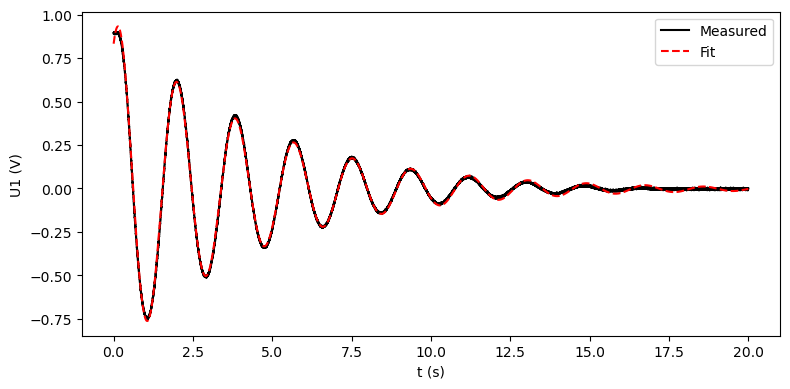

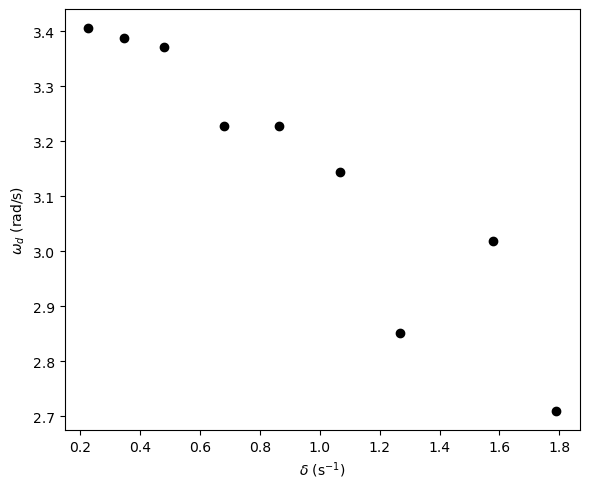


=== ω_d² vs δ² Fit Results ===
ω0 = 3.411510 ± 0.000057 rad/s
a (ω0²) = 11.638399 ± 0.000390
b (expected ≈ -1) = -1.249454 ± 0.000699


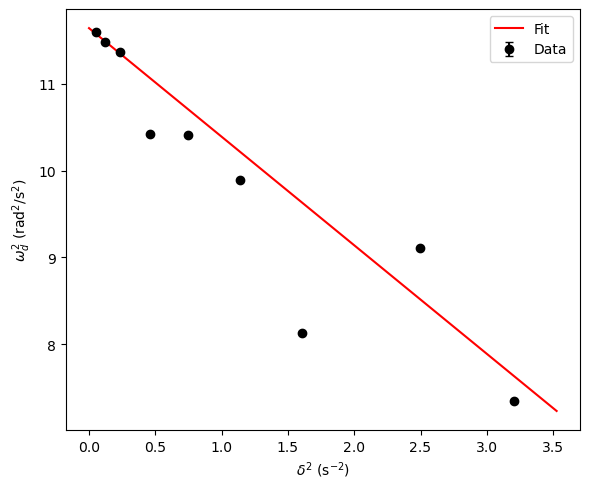


All Task 1 plots saved!


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

filenames = [
    "Task1-1.txt",
    "Task1-2.txt",
    "Task1-3.txt",
    "Task1-4.txt",
    "Task1-5.txt",
    "Task1-6.txt",
    "Task1-7.txt",
    "Task1-8.txt",
    "Task1-9.txt",
]

# Coil currents (A)
currents = np.array([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2])

# Index for example plot
example_index = 0

def load_task1_file(filename):
    """Load a Task 1 file (comma decimals, tab-separated)."""
    df = pd.read_csv(filename, sep="\t", decimal=",")
    df.columns = [c.strip() for c in df.columns]
    t = df["t (s)"].astype(float).values
    u = df["U1(V)"].astype(float).values
    return t, u


def damped_cosine(t, A, delta, omega, phi, C):
    """Model: A*exp(-δ t) cos(ω t + φ) + C."""
    return A * np.exp(-delta * t) * np.cos(omega * t + phi) + C


def initial_guess(t, u):
    """Initial guess using FFT frequency estimation."""
    dt = np.mean(np.diff(t))
    u0 = u - np.mean(u)
    N = len(u0)

    freqs = np.fft.rfftfreq(N, dt)
    spectrum = np.fft.rfft(u0)

    idx = np.argmax(np.abs(spectrum[1:])) + 1
    omega_guess = 2 * np.pi * freqs[idx]

    A_guess = 0.5 * (u.max() - u.min())
    C_guess = np.mean(u)
    delta_guess = 0.1
    phi_guess = 0.0

    return A_guess, delta_guess, omega_guess, phi_guess, C_guess

results = []

for I, fname in zip(currents, filenames):
    print(f"\nProcessing {fname} (I = {I:.1f} A)")
    t, u = load_task1_file(fname)

    # Choose fit data region (use full dataset for now)
    t_fit, u_fit = t, u

    # Initial guess
    p0 = initial_guess(t_fit, u_fit)

    lower = [0.0, 0.0, 0.0, -2*np.pi, -np.inf]
    upper = [np.inf, np.inf, np.inf,  2*np.pi,  np.inf]

    popt, pcov = curve_fit(
        damped_cosine,
        t_fit, u_fit,
        p0=p0,
        bounds=(lower, upper),
        maxfev=20000
    )

    perr = np.sqrt(np.diag(pcov))

    A_fit, delta_fit, omega_fit, phi_fit, C_fit = popt
    A_err, delta_err, omega_err, phi_err, C_err = perr

    T_d = 2 * np.pi / omega_fit
    T_d_err = (2 * np.pi / omega_fit**2) * omega_err

    results.append({
        "I (A)": I,
        "A": A_fit,           "A_err": A_err,
        "delta (1/s)": delta_fit, "delta_err (1/s)": delta_err,
        "omega_d (rad/s)": omega_fit, "omega_d_err (rad/s)": omega_err,
        "T_d (s)": T_d,       "T_d_err (s)": T_d_err,
        "phi (rad)": phi_fit, "phi_err (rad)": phi_err,
        "C (V)": C_fit,       "C_err (V)": C_err
    })

res_df = pd.DataFrame(results)
print("\n=== Completed fitting all files ===")
display(res_df)

res_df.to_csv("Task1_results_summary.csv", index=False)
print("\nSaved: Task1_results_summary.csv")

# 4.1 Example time series plot
idx = example_index
I_ex = res_df.loc[idx, "I (A)"]
A_ex  = res_df.loc[idx, "A"]
delta_ex = res_df.loc[idx, "delta (1/s)"]
omega_ex = res_df.loc[idx, "omega_d (rad/s)"]
phi_ex   = res_df.loc[idx, "phi (rad)"]
C_ex     = res_df.loc[idx, "C (V)"]

t_ex, u_ex = load_task1_file(filenames[idx])
u_fit_ex = damped_cosine(t_ex, A_ex, delta_ex, omega_ex, phi_ex, C_ex)

plt.figure(figsize=(8,4))
plt.plot(t_ex, u_ex, color="black", label="Measured")
plt.plot(t_ex, u_fit_ex, color="red", linestyle="--", label="Fit")
plt.xlabel("t (s)")
plt.ylabel("U1 (V)")
plt.legend()
plt.tight_layout()
plt.savefig("Task1_example_timeseries_fit.png", dpi=300, bbox_inches="tight")
plt.show()


# 4.2 ω_d vs δ
omega_d = res_df["omega_d (rad/s)"].values
omega_d_err = res_df["omega_d_err (rad/s)"].values
delta_vals = res_df["delta (1/s)"].values
delta_err = res_df["delta_err (1/s)"].values

plt.figure(figsize=(6,5))
plt.errorbar(delta_vals, omega_d, xerr=delta_err, yerr=omega_d_err,
             fmt="o", color="black", capsize=3)
plt.xlabel(r"$\delta$ (s$^{-1}$)")
plt.ylabel(r"$\omega_d$ (rad/s)")
plt.tight_layout()
plt.savefig("Task1_omega_vs_delta.png", dpi=300, bbox_inches="tight")
plt.show()


# 4.3 ω_d² vs δ² (linear fit)
omega2 = omega_d**2
delta2 = delta_vals**2
omega2_err = 2 * omega_d * omega_d_err

def linear(x, a, b):
    return a + b*x

popt_lin, pcov_lin = curve_fit(
    linear, delta2, omega2, sigma=omega2_err, absolute_sigma=True
)
a_fit, b_fit = popt_lin
a_err, b_err = np.sqrt(np.diag(pcov_lin))

omega0 = np.sqrt(a_fit)
omega0_err = 0.5 * a_err / omega0

print("\n=== ω_d² vs δ² Fit Results ===")
print(f"ω0 = {omega0:.6f} ± {omega0_err:.6f} rad/s")
print(f"a (ω0²) = {a_fit:.6f} ± {a_err:.6f}")
print(f"b (expected ≈ -1) = {b_fit:.6f} ± {b_err:.6f}")

# Plot
delta2_plot = np.linspace(0, 1.1 * delta2.max(), 300)
omega2_fit_plot = linear(delta2_plot, a_fit, b_fit)

plt.figure(figsize=(6,5))
plt.errorbar(delta2, omega2, yerr=omega2_err,
             fmt="o", color="black", capsize=3, label="Data")
plt.plot(delta2_plot, omega2_fit_plot, color="red", label="Fit")
plt.xlabel(r"$\delta^2$ (s$^{-2}$)")
plt.ylabel(r"$\omega_d^2$ (rad$^2$/s$^2$)")
plt.legend()
plt.tight_layout()
plt.savefig("Task1_omega2_vs_delta2_fit.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nAll Task 1 plots saved!")

Processing Task2-1.txt ...
Processing Task2-2.txt ...
Processing Task2-3.txt ...
Processing Task2-4.txt ...
Processing Task2-5.txt ...
Processing Task2-6.txt ...
Processing Task2-7.txt ...
Processing Task2-8.txt ...
Processing Task2-9.txt ...
Processing Task2-10.txt ...

=== Extracted Task 2 values (before fits) ===


,omega (rad/s),omega_err (rad/s),A_disk,A_disk_err,phase (rad),phase_err (rad),V_drive (V)
0,1.570796,0.15708,0.052412,0.000070,2.930082,0.001913,3.5
1,1.884956,0.15708,0.058711,0.000092,2.842222,0.002158,4.5
2,2.513274,0.15708,0.065354,0.000147,2.679098,0.003262,5.5
3,2.827433,0.15708,0.105575,0.000057,2.419890,0.000597,6.5
4,3.141593,0.15708,0.101256,0.000310,1.986030,0.004577,7.5
5,3.769911,0.15708,0.111077,0.000100,1.126688,0.001002,8.5
6,4.084070,0.15708,0.064807,0.000128,0.760141,0.002993,9.5
7,4.712389,0.15708,0.044532,0.000091,0.555654,0.002522,10.5
8,5.026548,0.15708,0.035588,0.000050,0.449197,0.001897,11.5
9,5.654867,0.15708,0.022253,0.000066,0.384620,0.003749,12.5


Saved: Task2_results_extracted.csv


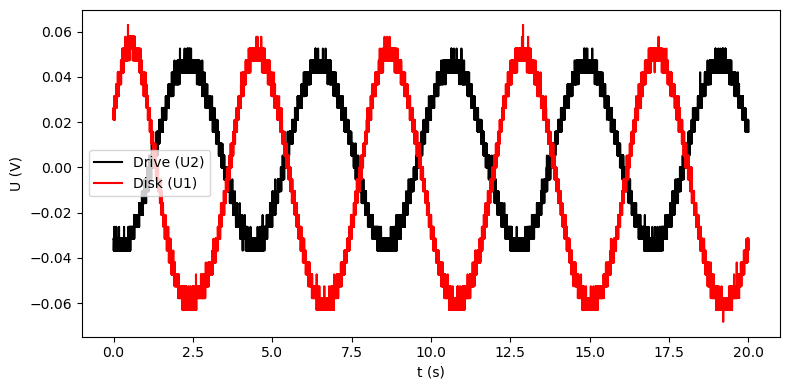


=== Resonance amplitude fit results ===
A0     = 0.492181 ± 0.000428
omega0 = 3.43304 ± 0.00049 rad/s
delta  = 0.515434 ± 0.000963 1/s
Q      = 3.33024 ± 0.00624


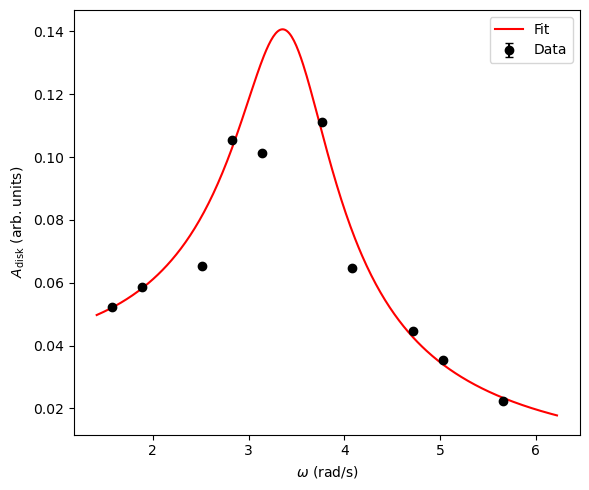

C:\Users\laiba\AppData\Local\Temp\ipykernel_24296\1835110602.py:268: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_phase, pcov_phase = curve_fit(



=== Phase fit results ===
omega0 (phase fit) = -3.97059e-06 ± inf rad/s
delta (phase fit)  = -7.03959 ± inf 1/s


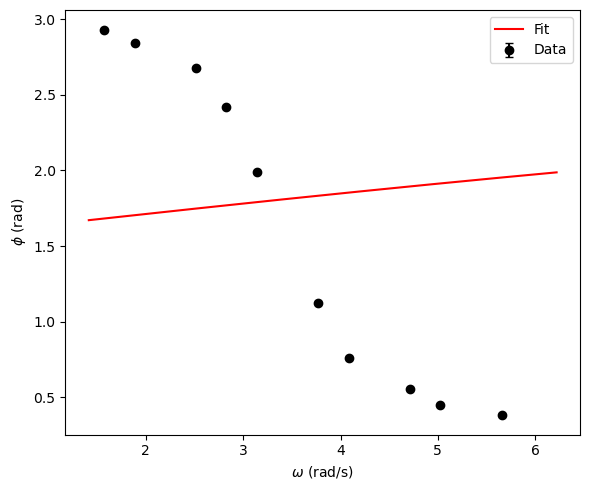


All Task 2 plots saved:
  - Task2_example_timeseries.png
  - Task2_resonance_curve.png
  - Task2_phase_curve.png
And extracted/fit data saved to CSV files.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq
from scipy.optimize import curve_fit

# Text files for the 10 drive voltages (adjust names if needed)
task2_files = [
    "Task2-1.txt",
    "Task2-2.txt",
    "Task2-3.txt",
    "Task2-4.txt",
    "Task2-5.txt",
    "Task2-6.txt",
    "Task2-7.txt",
    "Task2-8.txt",
    "Task2-9.txt",
    "Task2-10.txt",
]

# Optional: drive voltages used (just for reference / plotting labels if you want)
drive_voltages = np.linspace(3.5, 12.5, 10)  # 3.5 V ... 12.5 V

# Which dataset to use for the example time-series plot
example_index = 0  # 0 = Task2-1

def load_task2_file(filename):
    """
    Load Task 2 file (tab-separated, comma decimals, columns: t, U1, U2).
    U1 = disk / resonator (response)
    U2 = drive wheel / motor (input)
    """
    df = pd.read_csv(filename, sep="\t", decimal=",")
    df.columns = [c.strip() for c in df.columns]
    t = df["t (s)"].astype(float).to_numpy()
    u_disk = df["U1(V)"].astype(float).to_numpy()
    u_drive = df["U2(V)"].astype(float).to_numpy()
    return t, u_disk, u_drive


def extract_fft_ampl_phase(t, u):
    """
    For a *nearly pure sinusoid* u(t), return:
        - dominant frequency f (Hz),
        - angular frequency omega (rad/s),
        - amplitude A (same units as u),
        - phase phi (rad) of that Fourier component.

    Uses FFT, ignoring the DC component.
    """
    dt = np.mean(np.diff(t))
    N = len(t)

    # Remove mean to avoid DC dominance
    u0 = u - np.mean(u)

    # FFT
    U = rfft(u0)
    freqs = rfftfreq(N, dt)

    # ignore DC (index 0)
    mag = np.abs(U)
    idx_peak = np.argmax(mag[1:]) + 1

    f_peak = freqs[idx_peak]
    omega_peak = 2 * np.pi * f_peak

    # Amplitude of sinusoid corresponding to this Fourier mode
    # For real signals: A ≈ 2 * |U_k| / N
    A_peak = 2 * np.abs(U[idx_peak]) / N

    # Phase of this mode
    phi_peak = np.angle(U[idx_peak])

    return f_peak, omega_peak, A_peak, phi_peak, idx_peak, U, freqs


def phase_difference(phi_disk, phi_drive):
    """
    Phase lag of disk *relative to drive*:
        φ = φ_disk - φ_drive
    returned in range (-π, π].
    """
    dphi = phi_disk - phi_drive
    # bring into (-π, π] using atan2
    dphi = np.arctan2(np.sin(dphi), np.cos(dphi))
    return dphi

omega_list = []
omega_err_list = []
A_disk_list = []
A_disk_err_list = []
A_drive_list = []
A_drive_err_list = []
phase_list = []
phase_err_list = []

for fname in task2_files:
    print(f"Processing {fname} ...")
    t, u_disk, u_drive = load_task2_file(fname)

    # FFT on drive to get fundamental frequency
    f_drive, omega_drive, A_drive, phi_drive, idx_drive, U_drive, freqs = extract_fft_ampl_phase(t, u_drive)

    # FFT on disk at the *same* index to get response amplitude & phase
    dt = np.mean(np.diff(t))
    N = len(t)
    U_disk = rfft(u_disk - np.mean(u_disk))

    A_disk = 2 * np.abs(U_disk[idx_drive]) / N
    phi_disk = np.angle(U_disk[idx_drive])

    # Dominant angular frequency (we assume disk & drive are synchronous)
    omega = omega_drive

    # --- Uncertainties (rough estimates) ---
    # Frequency resolution: Δf ≈ 1 / (N * dt)
    df = 1.0 / (N * dt)
    domega = 2 * np.pi * df / 2.0  # half-bin as 1σ-ish estimate

    # Reconstruct signals from dominant component to estimate noise
    t_centered = t - t[0]
    u_drive_rec = A_drive * np.cos(omega * t_centered + phi_drive)
    u_disk_rec = A_disk * np.cos(omega * t_centered + phi_disk)

    noise_drive = u_drive - np.mean(u_drive) - u_drive_rec
    noise_disk = u_disk - np.mean(u_disk) - u_disk_rec

    noise_std_drive = np.std(noise_drive)
    noise_std_disk = np.std(noise_disk)

    # Very rough amplitude uncertainties: σ_A ~ noise / sqrt(N/2)
    A_drive_err = noise_std_drive / np.sqrt(N / 2.0)
    A_disk_err = noise_std_disk / np.sqrt(N / 2.0)

    # Very rough phase uncertainty (small-noise approx)
    # σ_φ ~ noise / (A * sqrt(N/2))
    phase_drive_err = noise_std_drive / (A_drive * np.sqrt(N / 2.0) + 1e-15)
    phase_disk_err = noise_std_disk / (A_disk * np.sqrt(N / 2.0) + 1e-15)

    phi = phase_difference(phi_disk, phi_drive)
    # add errors in quadrature
    phi_err = np.sqrt(phase_drive_err**2 + phase_disk_err**2)

    omega_list.append(omega)
    omega_err_list.append(domega)
    A_disk_list.append(A_disk)
    A_disk_err_list.append(A_disk_err)
    A_drive_list.append(A_drive)
    A_drive_err_list.append(A_drive_err)
    phase_list.append(phi)
    phase_err_list.append(phi_err)

# convert to numpy arrays
omega = np.array(omega_list)
omega_err = np.array(omega_err_list)
A_disk = np.array(A_disk_list)
A_disk_err = np.array(A_disk_err_list)
A_drive = np.array(A_drive_list)
A_drive_err = np.array(A_drive_err_list)
phase = np.array(phase_list)
phase_err = np.array(phase_err_list)

# sort by frequency just in case files not ordered
sort_idx = np.argsort(omega)
omega = omega[sort_idx]
omega_err = omega_err[sort_idx]
A_disk = A_disk[sort_idx]
A_disk_err = A_disk_err[sort_idx]
phase = phase[sort_idx]
phase_err = phase_err[sort_idx]
drive_voltages_sorted = drive_voltages[sort_idx]


# Put everything into a DataFrame for inspection & saving
task2_df = pd.DataFrame({
    "omega (rad/s)": omega,
    "omega_err (rad/s)": omega_err,
    "A_disk": A_disk,
    "A_disk_err": A_disk_err,
    "phase (rad)": phase,
    "phase_err (rad)": phase_err,
    "V_drive (V)": drive_voltages_sorted
})

print("\n=== Extracted Task 2 values (before fits) ===")
display(task2_df)

task2_df.to_csv("Task2_results_extracted.csv", index=False)
print("Saved: Task2_results_extracted.csv")

idx = example_index
t_ex, u_disk_ex, u_drive_ex = load_task2_file(task2_files[idx])

plt.figure(figsize=(8,4))
plt.plot(t_ex, u_drive_ex, color="black", label="Drive (U2)")
plt.plot(t_ex, u_disk_ex, color="red", label="Disk (U1)")
plt.xlabel("t (s)")
plt.ylabel("U (V)")
plt.legend()
plt.tight_layout()
plt.savefig("Task2_example_timeseries.png", dpi=300, bbox_inches="tight")
plt.show()

def resonance_amplitude(omega, A0, omega0, delta):
    """
    Theoretical amplitude of driven, damped oscillator:
        A(ω) = A0 / sqrt[(ω0^2 - ω^2)^2 + (2δω)^2]
    """
    return A0 / np.sqrt((omega0**2 - omega**2)**2 + (2*delta*omega)**2)


# initial guesses: use Task 1 ω0 ≈ 3.41 rad/s and δ ~ 0.48 (for 0.6 A)
A0_guess = np.max(A_disk) * ( (3.4**2 - omega[np.argmax(A_disk)]**2)**2 + (2*0.5*omega[np.argmax(A_disk)])**2 )**0.5
p0_amp = [A0_guess, 3.41, 0.5]

popt_amp, pcov_amp = curve_fit(
    resonance_amplitude,
    omega, A_disk,
    sigma=A_disk_err,
    p0=p0_amp,
    absolute_sigma=True,
    maxfev=20000
)

A0_fit, omega0_fit, delta_fit = popt_amp
A0_err, omega0_err, delta_err = np.sqrt(np.diag(pcov_amp))

Q_fit = omega0_fit / (2 * delta_fit)
Q_err = Q_fit * np.sqrt((omega0_err/omega0_fit)**2 + (delta_err/delta_fit)**2)

print("\n=== Resonance amplitude fit results ===")
print(f"A0     = {A0_fit:.6g} ± {A0_err:.3g}")
print(f"omega0 = {omega0_fit:.6g} ± {omega0_err:.3g} rad/s")
print(f"delta  = {delta_fit:.6g} ± {delta_err:.3g} 1/s")
print(f"Q      = {Q_fit:.6g} ± {Q_err:.3g}")


# Plot amplitude data + fit
omega_fit_grid = np.linspace(omega.min()*0.9, omega.max()*1.1, 400)
A_fit_grid = resonance_amplitude(omega_fit_grid, A0_fit, omega0_fit, delta_fit)

plt.figure(figsize=(6,5))
plt.errorbar(omega, A_disk, yerr=A_disk_err,
             fmt="o", color="black", capsize=3, label="Data")
plt.plot(omega_fit_grid, A_fit_grid, color="red", label="Fit")
plt.xlabel(r"$\omega$ (rad/s)")
plt.ylabel(r"$A_{\mathrm{disk}}$ (arb. units)")
plt.legend()
plt.tight_layout()
plt.savefig("Task2_resonance_curve.png", dpi=300, bbox_inches="tight")
plt.show()

def phase_theory(omega, omega0, delta):
    """
    Phase lag of the *response* relative to the drive for a damped,
    driven oscillator. Here we choose the convention where φ(ω0) ≈ -π/2.
    """
    return -np.arctan2(2*delta*omega, omega0**2 - omega**2)


# Use amplitude-fit ω0, δ as starting values
p0_phase = [omega0_fit, delta_fit]

# unwrap measured phase to make it continuous
phase_unwrapped = np.unwrap(phase)

popt_phase, pcov_phase = curve_fit(
    phase_theory,
    omega, phase_unwrapped,
    sigma=phase_err,
    p0=p0_phase,
    absolute_sigma=True,
    maxfev=20000
)

omega0_phase, delta_phase = popt_phase
omega0_phase_err, delta_phase_err = np.sqrt(np.diag(pcov_phase))

print("\n=== Phase fit results ===")
print(f"omega0 (phase fit) = {omega0_phase:.6g} ± {omega0_phase_err:.3g} rad/s")
print(f"delta (phase fit)  = {delta_phase:.6g} ± {delta_phase_err:.3g} 1/s")

phi_fit_grid = phase_theory(omega_fit_grid, omega0_phase, delta_phase)

plt.figure(figsize=(6,5))
plt.errorbar(omega, phase_unwrapped, yerr=phase_err,
             fmt="o", color="black", capsize=3, label="Data")
plt.plot(omega_fit_grid, phi_fit_grid, color="red", label="Fit")
plt.xlabel(r"$\omega$ (rad/s)")
plt.ylabel(r"$\phi$ (rad)")
plt.legend()
plt.tight_layout()
plt.savefig("Task2_phase_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nAll Task 2 plots saved:")
print("  - Task2_example_timeseries.png")
print("  - Task2_resonance_curve.png")
print("  - Task2_phase_curve.png")
print("And extracted/fit data saved to CSV files.")